In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Cari file dataset (jalan baik dari folder notebooks maupun folder utama)
kandidat = [Path("../data/goldstock_v1.csv"), Path("data/goldstock_v1.csv")]
DATA_PATH = next(p for p in kandidat if p.exists())
SHOT_DIR = DATA_PATH.parent.parent / "laporan" / "screenshots"
SHOT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Lokasi data:", DATA_PATH.resolve())
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Lokasi data: C:\Users\HP\Downloads\TUGAS\TA04-LSTM-Gold\data\goldstock_v1.csv
Ukuran data (baris, kolom): (2511, 7)


,Unnamed: 0,Date,Close,Volume,Open,High,Low
0,0,2024-01-19,2029.3,166078.0,2027.4,2041.9,2022.2
1,1,2024-01-18,2021.6,167013.0,2009.1,2025.6,2007.7
2,2,2024-01-17,2006.5,245194.0,2031.7,2036.1,2004.6
3,3,2024-01-16,2030.2,277995.0,2053.4,2062.8,2027.6
4,4,2024-01-12,2051.6,250946.0,2033.2,2067.3,2033.1


In [7]:
# Sel 2: bersihkan, jadikan Date sebagai index, hapus baris duplikat
df = df.drop(columns=["Unnamed: 0"])
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()

print("Baris sebelum pembersihan :", len(df))
print("Tanggal duplikat          :", df.index.duplicated().sum())
display(df[df.index.duplicated(keep=False)].head(6))

df = df[~df.index.duplicated(keep="first")]

print("Baris sesudah pembersihan :", len(df))
print("Rentang tanggal           :", df.index.min().date(), "sampai", df.index.max().date())
df.head()

Baris sebelum pembersihan : 2511
Tanggal duplikat          : 18


,Close,Volume,Open,High,Low
Date,,,,,
2021-10-29,1783.9,248553.0,1801.5,1802.9,1772.4
2021-10-29,1783.9,248553.0,1801.5,1802.9,1772.4
2021-11-01,1795.8,140366.0,1785.3,1797.5,1780.2
2021-11-01,1795.8,140366.0,1785.3,1797.5,1780.2
2021-11-02,1789.4,141590.0,1794.8,1797.8,1787.4
2021-11-02,1789.4,141590.0,1794.8,1797.8,1787.4


Baris sesudah pembersihan : 2493
Rentang tanggal           : 2014-01-22 sampai 2024-01-19


,Close,Volume,Open,High,Low
Date,,,,,
2014-01-22,1238.6,80262.0,1240.5,1243.5,1235.5
2014-01-23,1262.5,41697.0,1235.1,1267.1,1230.8
2014-01-24,1264.5,34998.0,1264.3,1273.2,1256.9
2014-01-27,1263.5,63419.0,1269.9,1280.1,1252.0
2014-01-28,1250.5,81426.0,1254.9,1261.9,1248.0


In [8]:
print("Nilai kosong per kolom:")
print(df.isna().sum())
print("\nIndex duplikat:", df.index.duplicated().sum())
print("Index terurut naik:", df.index.is_monotonic_increasing)
print()
df.describe()

Nilai kosong per kolom:
Close     0
Volume    0
Open      0
High      0
Low       0
dtype: int64

Index duplikat: 0
Index terurut naik: True



,Close,Volume,Open,High,Low
count,2493.000000,2493.000000,2493.000000,2493.000000,2493.000000
mean,1496.354272,186034.698355,1496.342479,1506.056839,1486.518091
std,298.575898,97739.426777,298.860270,301.009257,296.172036
min,1049.600000,1.000000,1051.500000,1062.700000,1045.400000
25%,1248.600000,126411.000000,1248.500000,1256.600000,1241.700000
50%,1331.400000,175222.000000,1332.000000,1340.900000,1324.500000
75%,1803.800000,234908.000000,1803.800000,1813.900000,1791.800000
max,2093.100000,787217.000000,2094.400000,2098.200000,2074.600000


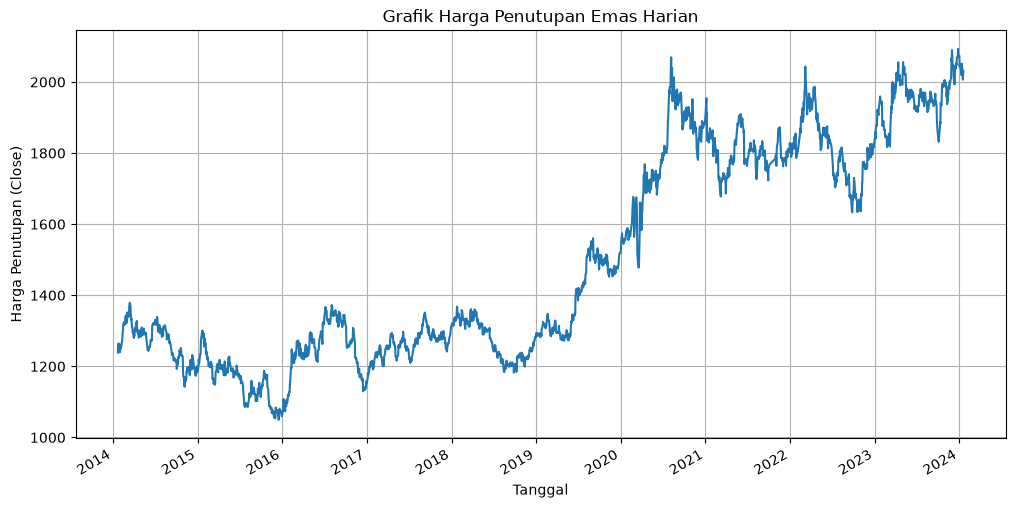

In [9]:
plt.figure(figsize=(12, 6))
df["Close"].plot()
plt.title("Grafik Harga Penutupan Emas Harian")
plt.xlabel("Tanggal")
plt.ylabel("Harga Penutupan (Close)")
plt.grid(True)
plt.savefig(SHOT_DIR / "plot_close_tp04.png", dpi=150, bbox_inches="tight")
plt.show()